# Task 2 — Feed-Forward Neural Network (MNIST digit classification)

Codveda ML Internship — Alen Gevorgyan (CV/AI/82079)

Building a plain feed-forward net (no conv layers) that classifies handwritten digits from MNIST. Task spec calls for explicit Input/Hidden/Output layers with backprop + gradient descent, so keeping it to Dense layers on purpose rather than reaching for a CNN.

Plan:
1. Load MNIST + look at a few sample digits
2. Normalize pixel values, flatten 28x28 -> 784
3. Build the feed-forward net
4. Train with a validation split + early stopping
5. Plot train vs val loss/accuracy curves
6. Evaluate on the test set + look at a few things it got wrong

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
print("tf version:", tf.__version__)

%matplotlib inline

2026-07-17 14:22:02.853236: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-07-17 14:22:02.856049: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-07-17 14:22:02.862807: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-07-17 14:22:02.876124: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-07-17 14:22:02.876165: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-07-17 14:22:02.885591: I tensorflow/core/platform/cpu_feature_guard.cc:

tf version: 2.16.2


## 1. Load the data

Using `keras.datasets.mnist` directly, it comes pre-split into train/test (60k / 10k) so no need to do that manually here.

In [2]:
from train_nn import load_mnist

X_train_raw, y_train_raw, X_test_raw, y_test_raw = load_mnist()
print("train:", X_train_raw.shape, y_train_raw.shape)
print("test :", X_test_raw.shape, y_test_raw.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
loaded MNIST via keras.datasets (train: (60000, 28, 28), test: (10000, 28, 28))
train: (60000, 28, 28) (60000,)
test : (10000, 28, 28) (10000,)


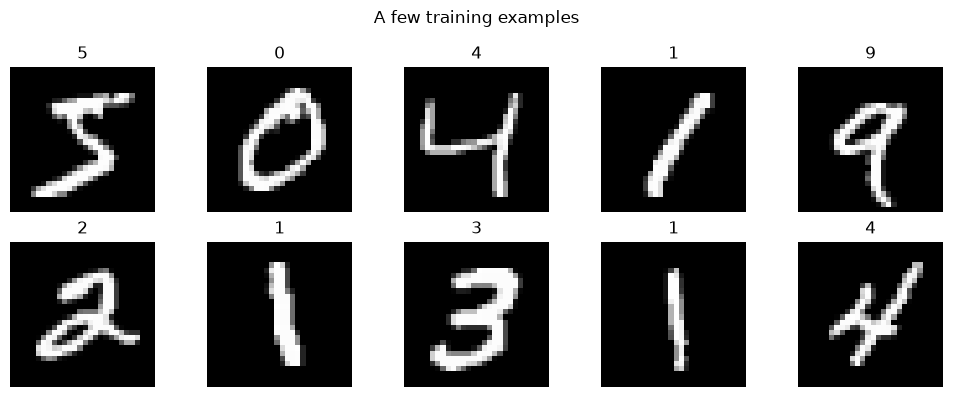

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train_raw[i], cmap="gray")
    ax.set_title(str(y_train_raw[i]))
    ax.axis("off")
plt.suptitle("A few training examples")
plt.tight_layout()
plt.show()

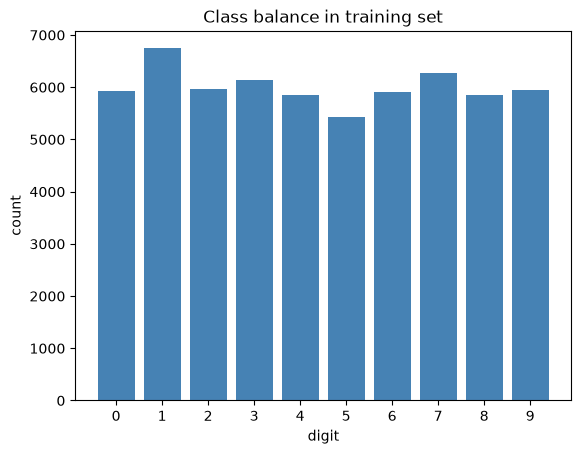

In [4]:
unique, counts = np.unique(y_train_raw, return_counts=True)
plt.bar(unique, counts, color="steelblue")
plt.xticks(unique)
plt.xlabel("digit")
plt.ylabel("count")
plt.title("Class balance in training set")
plt.show()

Classes are close enough to balanced that I'm not worried about class weighting here, unlike the churn task.

## 2. Preprocess

Flatten each 28x28 image to a 784-length vector and rescale pixel values from 0-255 down to 0-1. Rescaling matters more than I expected the first time I skipped it -- training was way less stable with raw 0-255 inputs.

In [5]:
from train_nn import prepare_data, NUM_PIXELS

X_train, X_test, y_train, y_test = prepare_data(X_train_raw, y_train_raw, X_test_raw, y_test_raw)
print("flattened shape:", X_train.shape)
print("pixel value range after scaling:", X_train.min(), "to", X_train.max())

flattened shape: (60000, 784)
pixel value range after scaling: 0.0 to 1.0


## 3. Build the model

`Input(784) -> Dense(256, relu) -> Dropout(0.3) -> Dense(128, relu) -> Dropout(0.3) -> Dense(64, relu) -> Dense(10, softmax)`

Went through a couple of smaller versions first (just one hidden layer of 64) and accuracy topped out noticeably lower, so scaled it up. Dropout after the first two dense layers because without it training accuracy pulls way ahead of validation accuracy pretty fast.

In [6]:
from network_architecture import build_model

model = build_model(input_dim=X_train.shape[1], num_classes=10)
model.summary()

Model: "mnist_feedforward_net"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)          │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_3 (Dense)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,762 (948.29 KB)

 Trainable params: 242,762 (948.29 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Train

`EarlyStopping` on val_loss, patience of 5 -- with a dataset this size epochs take a while so no point letting it run past the point it's actually improving.

In [7]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_split=0.10,
    epochs=30,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1,
)

Epoch 1/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8676 - loss: 0.4243 - val_accuracy: 0.9648 - val_loss: 0.1174
Epoch 2/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9464 - loss: 0.1767 - val_accuracy: 0.9735 - val_loss: 0.0883
Epoch 3/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9598 - loss: 0.1332 - val_accuracy: 0.9755 - val_loss: 0.0795
Epoch 4/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9660 - loss: 0.1098 - val_accuracy: 0.9763 - val_loss: 0.0736
Epoch 5/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9706 - loss: 0.0937 - val_accuracy: 0.9812 - val_loss: 0.0672
Epoch 6/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9729 - loss: 0.0864 - val_accuracy: 0.9790 - val_loss: 0.0681
Epoch 7/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9767 - loss: 0.0757 - val_accuracy: 0.9805 - val_loss: 0.0675
Epoch 8/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9793 - loss: 0.0661 - val_accuracy: 0.

## 5. Loss / accuracy curves

saved training curves -> ../outputs/loss_accuracy_curves.png


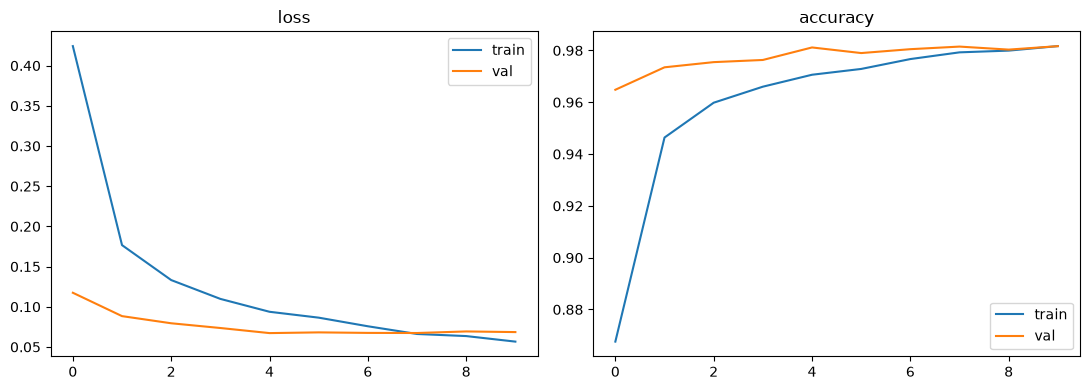

In [8]:
from train_nn import plot_curves

plot_curves(history)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="val")
axes[0].set_title("loss"); axes[0].legend()
axes[1].plot(history.history["accuracy"], label="train")
axes[1].plot(history.history["val_accuracy"], label="val")
axes[1].set_title("accuracy"); axes[1].legend()
plt.tight_layout()
plt.show()

Train/val curves stay pretty close together for the first several epochs, then train accuracy starts to pull ahead a bit near the end -- early stopping is grabbing the weights from before that gap widens too much, which is exactly what I wanted it to do.

## 6. Test set evaluation

In [9]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"test loss: {test_loss:.4f} | test accuracy: {test_acc:.4f}")

y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(y_test, y_pred))

test loss: 0.0770 | test accuracy: 0.9772
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 629us/step
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.97      0.98      0.98      1032
           3       0.98      0.97      0.97      1010
           4       0.97      0.99      0.98       982
           5       0.99      0.97      0.98       892
           6       0.98      0.98      0.98       958
           7       0.97      0.98      0.97      1028
           8       0.98      0.96      0.97       974
           9       0.97      0.96      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



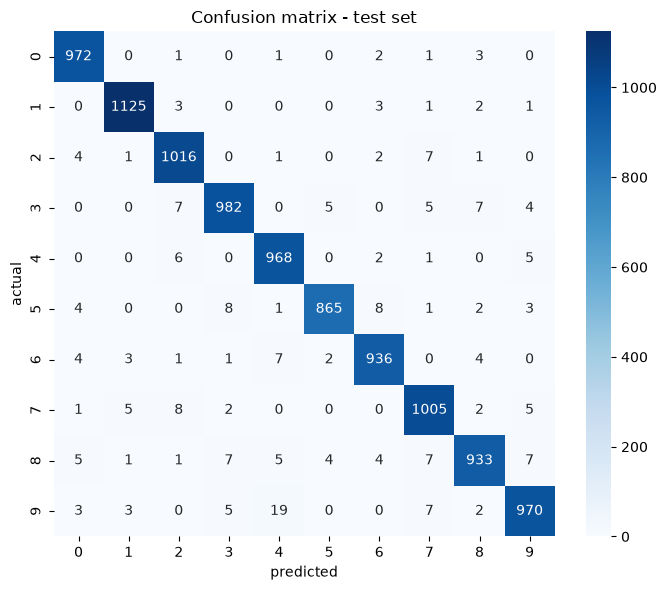

In [10]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("predicted"); plt.ylabel("actual")
plt.title("Confusion matrix - test set")
plt.tight_layout()
plt.show()

Curious what it's actually getting wrong -- pulling a handful of misclassified digits to eyeball.

228 misclassified out of 10000


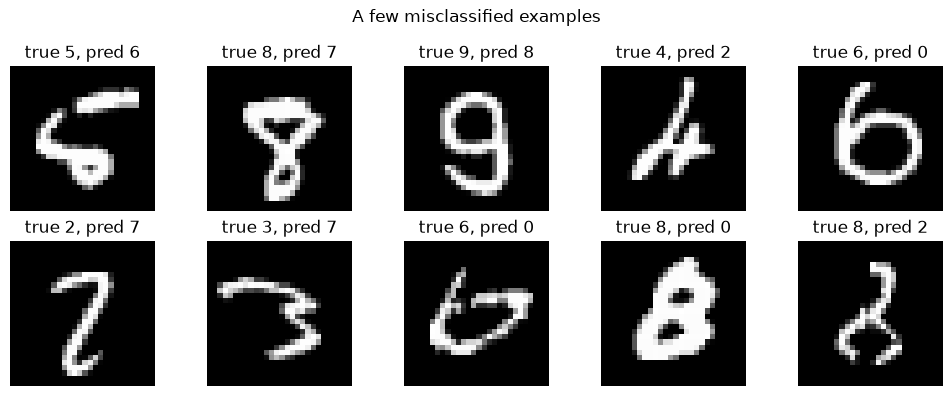

In [11]:
wrong_idx = np.where(y_pred != y_test)[0]
print(f"{len(wrong_idx)} misclassified out of {len(y_test)}")

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, idx in zip(axes.flat, wrong_idx[:10]):
    ax.imshow(X_test_raw[idx], cmap="gray")
    ax.set_title(f"true {y_test[idx]}, pred {y_pred[idx]}")
    ax.axis("off")
plt.suptitle("A few misclassified examples")
plt.tight_layout()
plt.show()